<a href="https://colab.research.google.com/github/jayatisingh3108-cloud/ad-click-prediction/blob/main/CTR_Prediction_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing required libraries


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

Loading the dataset

In [21]:
# Load the dataset
df = pd.read_csv("https://raw.githubusercontent.com/jayatisingh3108-cloud/ad-click-prediction/main/advertising.csv")

# Show first 5 rows
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


Exploring the dataset

In [22]:
# Check data info
df.info()

# Get summary statistics
df.describe()

# Check for missing values
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   object 
 5   City                      1000 non-null   object 
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   object 
 8   Timestamp                 1000 non-null   object 
 9   Clicked on Ad             1000 non-null   int64  
dtypes: float64(3), int64(3), object(4)
memory usage: 78.3+ KB


,0
Daily Time Spent on Site,0
Age,0
Area Income,0
Daily Internet Usage,0
Ad Topic Line,0
City,0
Male,0
Country,0
Timestamp,0
Clicked on Ad,0


Data preprocessing

In [23]:
# Remove duplicates
df.drop_duplicates(inplace=True)

# Convert 'Timestamp' to datetime
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# Extract hour and day of week
df['hour'] = df['Timestamp'].dt.hour
df['dayofweek'] = df['Timestamp'].dt.dayofweek

# View first few rows
df.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad,hour,dayofweek
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0,0,6
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0,1,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0,20,6
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0,2,6
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0,3,4


Data Visualization

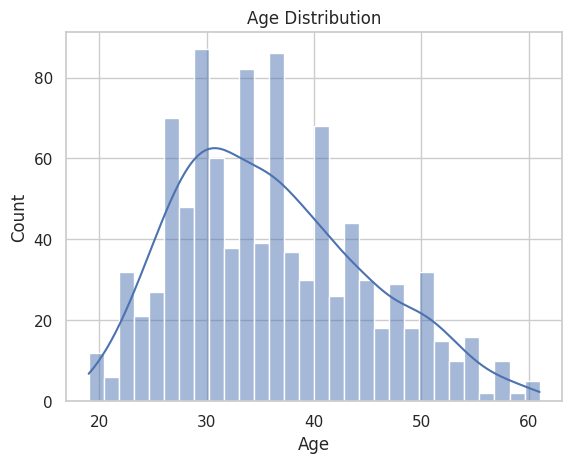

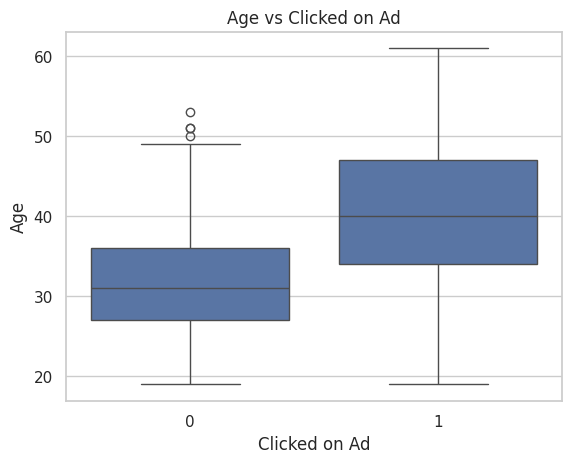

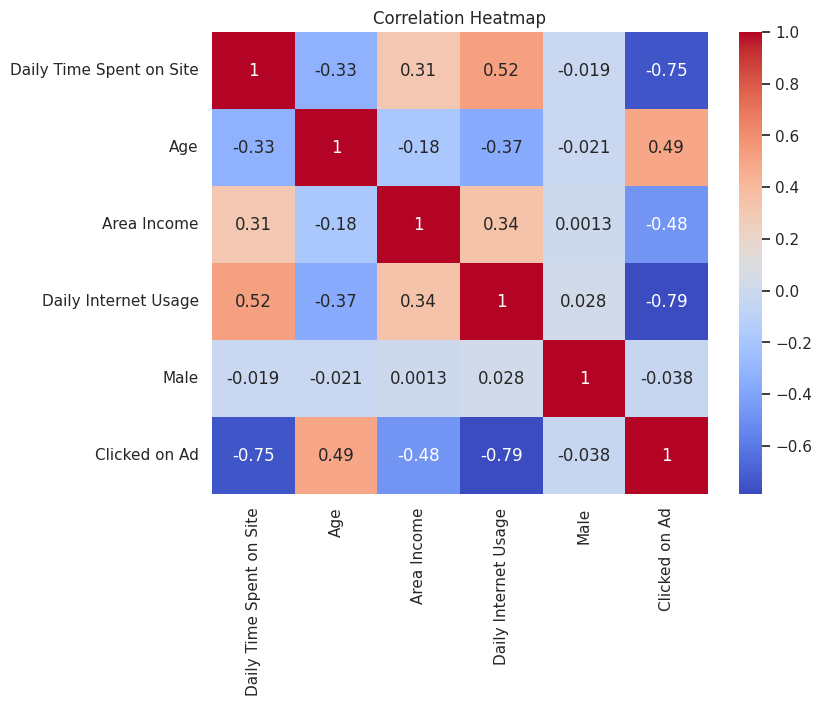

In [24]:
# Distribution of Age
sns.histplot(df['Age'], bins=30, kde=True)
plt.title("Age Distribution")
plt.show()

# Relationship between Age and Clicked on Ad
sns.boxplot(x='Clicked on Ad', y='Age', data=df)
plt.title("Age vs Clicked on Ad")
plt.show()

# Select only numeric columns
numeric_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(8,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


Select Features and Target

In [25]:
X = df[['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male']]
y = df['Clicked on Ad']


Splitting Data into Training and Testing Sets

In [26]:
X = df[['Daily Time Spent on Site', 'Age', 'Area Income',
        'Daily Internet Usage', 'Male']]
y = df['Clicked on Ad']

# Split into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,
                                                    random_state=42)

# Check shape of splits
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (700, 5)
Testing data: (300, 5)


In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Training model using Logistic Regression and making predictions

In [28]:
from sklearn.linear_model import LogisticRegression

# Create model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
# Predict on test data
y_pred = model.predict(X_test)

# Compare first few predictions
print(y_pred[:10])


[1 1 1 1 0 0 0 1 0 1]


Evaluating Business Metric: Precision at Top 5%

In [29]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]
top_n = int(0.05 * len(y_prob))
top_users = np.argsort(y_prob)[-top_n:]
precision_top_5 = y_test.iloc[top_users].mean()

print("Precision at Top 5%:", round(precision_top_5, 3))

Precision at Top 5%: 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


Evaluating model accuracy

In [30]:
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Evaluation
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nAccuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[142   4]
 [  6 148]]

Accuracy Score: 0.9666666666666667

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.97      0.97       146
           1       0.97      0.96      0.97       154

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



Visualizing confusion matrix

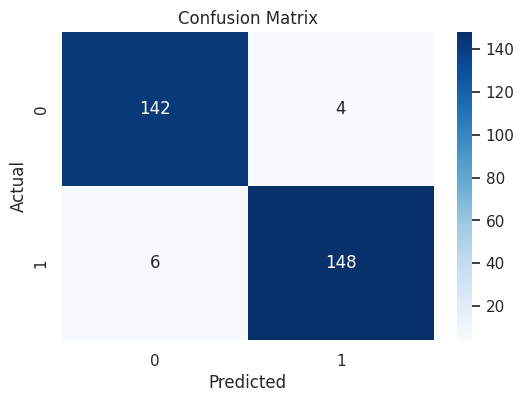

In [31]:
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Saving model for future use

In [32]:
import joblib

# Save model
joblib.dump(model, 'ctr_model.pkl')

['ctr_model.pkl']

### Conclusion

This model successfully predicts whether a user will click on an online advertisement based on their age, gender, internet usage, and other factors. Using Logistic Regression, the model achieved around **96-97% accuracy**. Data visualizations showed that younger users with high internet usage are more likely to click on ads.
